<a href="https://colab.research.google.com/github/siyunggu/CXR_CV/blob/main/CXR_CV_3_ResNet18_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 필요한 라이브러리 및 데이터 불러오기


In [1]:
import os, pandas as pd
from PIL import Image
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

In [2]:
# 코랩으로 하시는 분들
!pip install scikit-optimize imbalanced-learn -q
# 이거 안깔면 오류뜹니다. 그리고 데이터 드라이브에서 마운트하면 오래걸림

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.4 MB/s eta 0:00:00


In [3]:
# Colab에서 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# 이미지 데이터 불러오기
!cp "/content/drive/MyDrive/프로젝트/CV해커톤/img.zip" /content/

In [5]:
# 압축해제
!unzip -q /content/img.zip -d /content/img  #-d 뒤에는 압축 푼 파일명(일반적으로.zip만 지우기)

In [6]:
# 파일/폴더 목록이 잘 뜨는지 확인
os.listdir('/content/img')

['train', 'test', '__MACOSX']

In [7]:
print(os.listdir('/content/img/train')[:5])
print(os.listdir('/content/img/test')[:5])

['train_0595.png', 'train_4659.png', 'train_4418.png', 'train_1487.png', 'train_1270.png']
['test_0184.png', 'test_0419.png', 'test_0598.png', 'test_0166.png', 'test_0177.png']


In [8]:
# csv 데이터 불러오기
df1 = pd.read_csv('train.csv')
df2 = pd.read_csv('test.csv')
df3 = pd.read_csv('sample_submission.csv')

In [9]:
print("Train:", df1.shape, df1.columns.tolist())
print("Test:", df2.shape, df2.columns.tolist())
print("Sample:", df3.shape, df3.columns.tolist())

Train: (5216, 2) ['file_name', 'label']
Test: (624, 1) ['file_name']
Sample: (624, 2) ['file_name', 'label']


## 2. 이미지 전처리 설정하기

이미지를 모델에 넣기 전에 몇 가지 작업을 해야 합니다. 왜 이런 작업이 필요할까요?

우리가 가진 이미지들은 크기도 다르고, 어떤 건 컬러이고 어떤 건 흑백일 수도 있습니다. 하지만 딥러닝 모델은 모든 입력이 똑같은 형태여야 처리할 수 있어요.

baseline 코드에서는 Grayscale()로 이미지를 흑백으로 바꿉니다. 또한, 모든 이미지를 128×128 픽셀 크기로 통일하고 PyTorch가 이해할 수 있는 숫자 배열 형태로 바꿔줍니다.


In [10]:
# 이미지 크기 확인
Img = Image.open('/content/img/train/train_2550.png')
Img = np.array(Img)
print(Img.shape)

Img1 = Image.open('/content/img/test/test_0552.png')
Img1 = np.array(Img1)
print(Img1.shape)

(224, 224)
(936, 1350)


In [11]:
# train에서는 이미 크기와 여백이 통일된 상태. test에서는 각각의 이미지 크기가 다름

from collections import Counter

# CSV에 적힌 파일 목록 불러오기
train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test.csv")

# 이미지 크기 확인
def check_image_sizes(df, folder):
    sizes = []

    for filename in df["file_name"]:
        path = os.path.join(folder, filename)

        with Image.open(path) as img:
            sizes.append(img.size)  # (가로, 세로)

    return Counter(sizes)

train_sizes = check_image_sizes(
    train_df, "/content/img/train"
)
test_sizes = check_image_sizes(
    test_df, "/content/img/test"
)

print("Train 이미지 크기 종류:", len(train_sizes))
print("Train에서 많은 크기 TOP 5:", train_sizes.most_common(5))

print("\nTest 이미지 크기 종류:", len(test_sizes))
print("Test에서 많은 크기 TOP 5:", test_sizes.most_common(5))


Train 이미지 크기 종류: 1
Train에서 많은 크기 TOP 5: [((224, 224), 5216)]

Test 이미지 크기 종류: 598
Test에서 많은 크기 TOP 5: [((1112, 736), 3), ((1088, 576), 2), ((1368, 904), 2), ((1112, 600), 2), ((1232, 888), 2)]


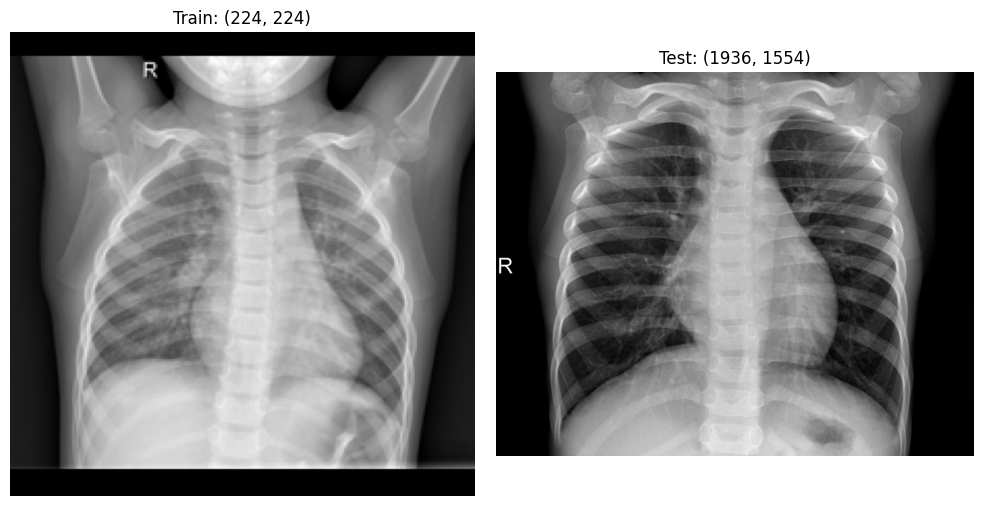

In [12]:
# traim test 실제 이미지 확인

import matplotlib.pyplot as plt


train_name = train_df["file_name"].iloc[0]
test_name = test_df["file_name"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, path, title in [
    (axes[0], os.path.join("/content/img/train", train_name), "Train"),
    (axes[1], os.path.join("/content/img/test", test_name), "Test")
]:
    img = Image.open(path).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{title}: {img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [13]:
# 전처리

from PIL import Image, ImageOps
from torchvision import transforms
import cv2
import random

# 직사각형 이미지를 검은 여백으로 정사각형 만들기
class PadToSquare:
    def __call__(self, img):
        width, height = img.size

        # 이미 정사각형이면 그대로 사용
        if width == height:
            return img

        # 긴 변에 맞춰 짧은 변 양쪽에 검은 여백 추가
        size = max(width, height)
        left = (size - width) // 2
        top = (size - height) // 2
        right = size - width - left
        bottom = size - height - top

        return ImageOps.expand(
            img,
            border=(left, top, right, bottom),
            fill=0
        )


# 이미지별 대비 보정(CLAHE): 촬영 조건(밝기·대비) 차이를 줄여줌
class ApplyCLAHE:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img):
        arr = np.array(img.convert("L"))
        return Image.fromarray(self.clahe.apply(arr))


# ---- 실험 스위치 (결과 비교용으로 켜고 끌 수 있음) ----
AUTOCROP = True         # 검은 여백을 잘라낸 뒤 정사각형으로 맞춤 (train/test 구도 통일)
TEST_LIKE_AUG = True    # 학습 때 test처럼 크기·구도·기울기가 제각각인 상황을 흉내냄
TAG = "v4"              # 저장 파일 이름에 붙는 꼬리표 (설정을 바꾸면 TAG도 바꾸세요)

IMG_SIZE = 128   # 실험 결과 128이 가장 좋았음 (112, 224는 테스트 점수가 더 낮음)

# ImageNet 평균/표준편차를 흑백으로 합친 근사값
NORM_MEAN, NORM_STD = [0.449], [0.226]


# 검은 여백 제거: 영상 내용이 있는 영역만 남김
class AutoCropBorders:
    def __init__(self, thresh=15, line_ratio=0.02, min_area_ratio=0.3):
        self.thresh = thresh
        self.line_ratio = line_ratio
        self.min_area_ratio = min_area_ratio

    def __call__(self, img):
        arr = np.array(img.convert("L"))
        mask = arr > self.thresh
        rows = np.where(mask.mean(axis=1) > self.line_ratio)[0]
        cols = np.where(mask.mean(axis=0) > self.line_ratio)[0]
        if len(rows) == 0 or len(cols) == 0:
            return img
        top, bottom = rows[0], rows[-1] + 1
        left, right = cols[0], cols[-1] + 1
        # 너무 많이 잘리면(내용이 너무 작게 잡히면) 원본 유지
        if (bottom - top) * (right - left) < self.min_area_ratio * arr.shape[0] * arr.shape[1]:
            return img
        return img.crop((left, top, right, bottom))


# 정사각형이 아니게 무작위로 잘라냄 -> PadToSquare에서 여백이 생겨 test처럼 구도가 다양해짐
class RandomCropKeepAspect:
    def __init__(self, min_frac=0.8, p=0.7):
        self.min_frac = min_frac
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        cw = int(w * random.uniform(self.min_frac, 1.0))
        ch = int(h * random.uniform(self.min_frac, 1.0))
        x0 = random.randint(0, w - cw)
        y0 = random.randint(0, h - ch)
        return img.crop((x0, y0, x0 + cw, y0 + ch))


# 공통 앞단 전처리: 흑백 -> (여백 제거) -> CLAHE
pre_ops = [transforms.Grayscale()]
if AUTOCROP:
    pre_ops.append(AutoCropBorders())
pre_ops.append(ApplyCLAHE())

# 학습·검증·테스트에 공통으로 적용할 기본 전처리
base_transform = transforms.Compose(pre_ops + [
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])


## 3. 학습 데이터셋 만들기

이 부분은 우리의 학습 데이터를 정리하는 클래스입니다.

PyTorch에서는 데이터를 Dataset 클래스로 만들어야 합니다. 이 클래스는 세 가지 기능이 있어야 해요. 처음 시작할 때 CSV 파일을 읽어서 이미지 파일 이름들과 정답 라벨들을 기억해두고, "총 몇 개의 데이터가 있나요?"라고 물어볼 때 답해주고, "i번째 데이터를 주세요"라고 요청할 때 해당 이미지를 불러와서 전처리한 후 정답과 함께 돌려줍니다.

여기서 중요한 점은 이미지 파일을 미리 다 불러오지 않고, 필요할 때마다 하나씩 불러온다는 것입니다. 만약 이미지가 수천 개라면 메모리가 부족할 수 있거든요.


In [14]:
from torchvision import transforms

# 학습 데이터에만 적용할 데이터 증강
# test는 전처리/기울기 보정이 안 된 원본이라, 그 상황을 흉내내도록 구성
train_ops = list(pre_ops)
if TEST_LIKE_AUG:
    train_ops.append(RandomCropKeepAspect(min_frac=0.8, p=0.7))   # 구도/여백 다양화

train_transform = transforms.Compose(train_ops + [
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # 기울기: 최대 20도 회전 (test는 기울기 보정이 안 돼 있음)
    transforms.RandomRotation(degrees=20 if TEST_LIKE_AUG else 10),

    # 최대 8% 이동, 85~115% 확대/축소
    transforms.RandomAffine(
        degrees=0,
        translate=(0.08, 0.08),
        scale=(0.85, 1.15)
    ),

    # 밝기·대비 변화
    transforms.ColorJitter(brightness=0.3, contrast=0.3),

    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])


In [15]:
class TrainCSV(Dataset):
    def __init__(self, csv_path="/content/train.csv",
                 root_dir="/content/img/train",
                 transform=None):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.root = root_dir
        self.tf = transform if transform is not None else base_transform  #학습용과 검증용 데이터 따로 하기 위함

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img_path = os.path.join(self.root, self.files[i])
        img = Image.open(img_path).convert("L")
        x = self.tf(img)
        y = self.labels[i]
        return x, y


In [16]:
train_dataset = TrainCSV()

x, y = train_dataset[0]

print("이미지 텐서 크기:", x.shape)
print("레이블:", y)

이미지 텐서 크기: torch.Size([1, 128, 128])
레이블: 0


## 4. 테스트 데이터셋 만들기

해커톤에서의 테스트 데이터셋은 정답이 없습니다!

테스트 데이터는 우리가 예측해야 하는 데이터이기 때문에 당연히 정답을 모르죠. 그래서 이미지만 반환하고 라벨은 반환하지 않습니다.

이것이 바로 대회의 핵심입니다. 학습 데이터로 모델을 훈련시킨 후, 처음 보는 테스트 데이터에 대해 정답을 맞춰야 하는 거예요.


In [17]:
class TestCSV(Dataset):
    def __init__(self, csv_path="/content/test.csv",
                 root_dir="/content/img/test"):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.root = root_dir
        self.tf = base_transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img_path = os.path.join(self.root, self.files[i])
        img = Image.open(img_path).convert("L")
        x = self.tf(img)
        return x


In [18]:
test_dataset = TestCSV()

x = test_dataset[0]

print("테스트 이미지 텐서 크기:", x.shape)
print("테스트 데이터 개수:", len(test_dataset))

테스트 이미지 텐서 크기: torch.Size([1, 128, 128])
테스트 데이터 개수: 624


## 5. 데이터로더 설정하기

데이터셋을 만들었다면 이제 이것을 모델에게 효율적으로 전달해주는 DataLoader가 필요합니다.

왜 DataLoader가 필요할까요? 만약 이미지가 1000개라면, 1000개를 한 번에 모델에 넣을 수 있을까요? 아마 컴퓨터 메모리가 부족할 거예요. 그래서 32개씩 나누어서 처리하는 것입니다. 이렇게 나누어진 묶음을 '배치(batch)'라고 합니다.

batch_size=32는 한 번에 32개 이미지를 처리한다는 뜻입니다. shuffle=True는 학습 데이터의 순서를 섞어서 모델이 편향되지 않게 하고, shuffle=False는 테스트 데이터의 순서를 유지해야 제출할 때 파일명과 예측 결과가 올바르게 매칭되도록 합니다.


In [19]:
train_loader = DataLoader(
    TrainCSV("/content/train.csv", "/content/img/train"),
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    TestCSV("/content/test.csv", "/content/img/test"),
    batch_size=64,
    shuffle=False
)

## 6. 데이터 증강

In [20]:
from torchvision import transforms

# 학습 데이터에만 적용할 데이터 증강
# test는 전처리/기울기 보정이 안 된 원본이라, 그 상황을 흉내내도록 구성
train_ops = list(pre_ops)
if TEST_LIKE_AUG:
    train_ops.append(RandomCropKeepAspect(min_frac=0.8, p=0.7))   # 구도/여백 다양화

train_transform = transforms.Compose(train_ops + [
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # 기울기: 최대 20도 회전 (test는 기울기 보정이 안 돼 있음)
    transforms.RandomRotation(degrees=20 if TEST_LIKE_AUG else 10),

    # 최대 8% 이동, 85~115% 확대/축소
    transforms.RandomAffine(
        degrees=0,
        translate=(0.08, 0.08),
        scale=(0.85, 1.15)
    ),

    # 밝기·대비 변화
    transforms.ColorJitter(brightness=0.3, contrast=0.3),

    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])


In [21]:
# 데이터 증강 적용 확인
train_dataset = TrainCSV()

x, y = train_dataset[0]

print("이미지 텐서 크기:", x.shape)
print("레이블:", y)

이미지 텐서 크기: torch.Size([1, 128, 128])
레이블: 0


## 데이터 분리하기

In [22]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

# 전체 데이터에서 학습용 / 검증용 인덱스 분리
indices = list(range(len(train_dataset)))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=train_dataset.labels
)

print("학습 데이터 개수:", len(train_indices))
print("검증 데이터 개수:", len(val_indices))


학습 데이터 개수: 4172
검증 데이터 개수: 1044


In [23]:
# 학습용: 데이터 증강 적용
train_dataset = TrainCSV(transform=train_transform)

# 검증용: 기본 전처리만 적용
val_dataset = TrainCSV(transform=base_transform)

# 같은 인덱스 분할을 각각 적용
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = DataLoader(
    train_subset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_subset, batch_size=32, shuffle=False
)

print("학습 배치 수:", len(train_loader))
print("검증 배치 수:", len(val_loader))


학습 배치 수: 131
검증 배치 수: 33


In [24]:
from collections import Counter

print("전체 레이블:", Counter(train_dataset.labels))
print("학습 레이블:", Counter(train_dataset.labels[i] for i in train_indices))
print("검증 레이블:", Counter(val_dataset.labels[i] for i in val_indices))

전체 레이블: Counter({1: 3875, 0: 1341})
학습 레이블: Counter({1: 3099, 0: 1073})
검증 레이블: Counter({1: 776, 0: 268})


/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 50857 (\N{HANGUL SYLLABLE YONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2558/3966636779.py:23: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) DejaVu Sans.
  plt.tig

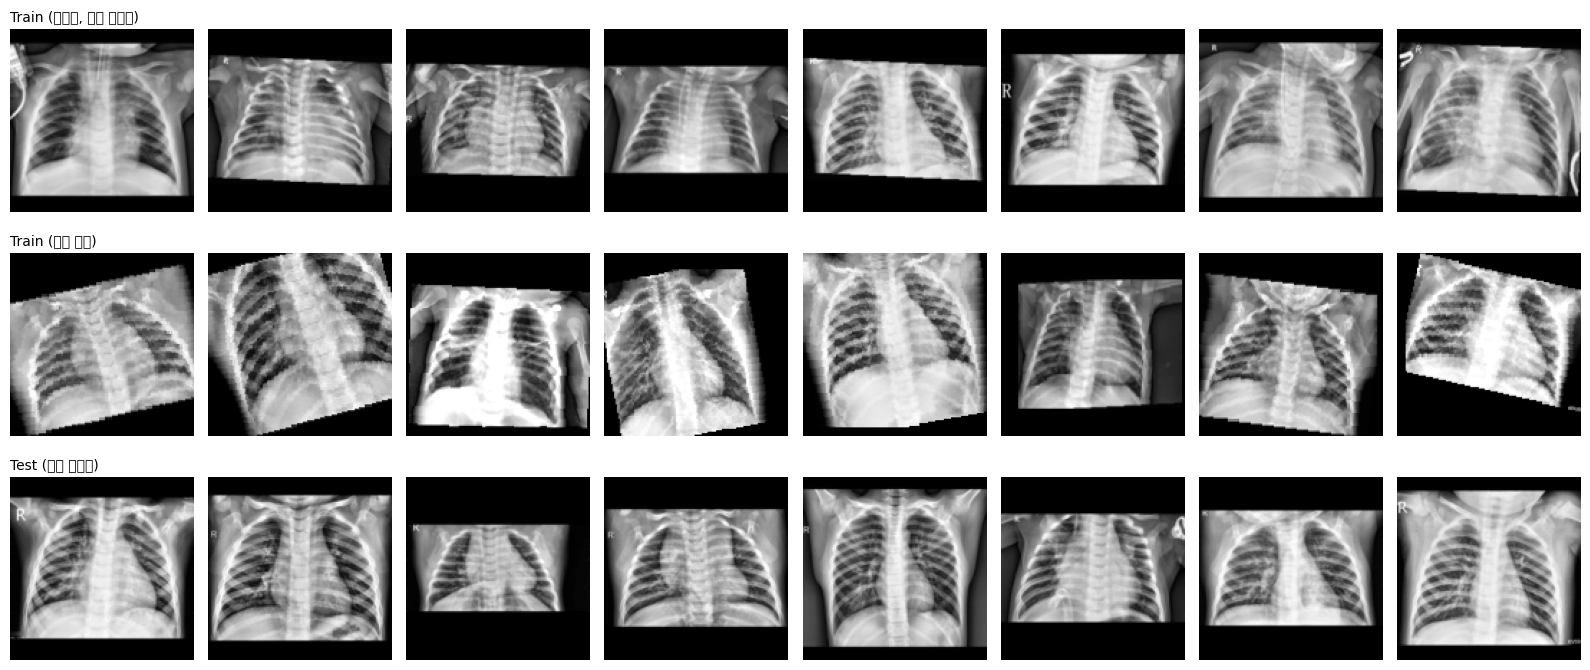

In [25]:
# 전처리 결과 비교: 검증(기본 전처리) / 학습(증강 적용) / 테스트(기본 전처리)
import matplotlib.pyplot as plt

def denorm(x):
    return (x * NORM_STD[0] + NORM_MEAN[0]).clamp(0, 1).squeeze(0).numpy()

n = 8
rng = np.random.RandomState(0)
rows = [
    ("Train (검증용, 기본 전처리)", val_dataset, rng.choice(val_indices, n, replace=False)),
    ("Train (증강 적용)", train_dataset, rng.choice(train_indices, n, replace=False)),
    ("Test (기본 전처리)", test_dataset, rng.choice(len(test_dataset), n, replace=False)),
]

fig, axes = plt.subplots(3, n, figsize=(2 * n, 7))
for r, (name, ds, idxs) in enumerate(rows):
    for c, idx in enumerate(idxs):
        item = ds[int(idx)]
        x = item[0] if isinstance(item, tuple) else item
        axes[r, c].imshow(denorm(x), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. ResNet18 모델 만들기

기존의 간단한 CNN 대신 **ResNet18**을 사용합니다. ResNet18은 18개 층으로 이루어진 CNN으로, 잔차 연결(skip connection)이 있어서 층이 깊어도 학습이 안정적입니다.

- **사전학습 가중치**: ImageNet으로 미리 학습된 가중치(`ResNet18_Weights.DEFAULT`)에서 시작합니다. 적은 데이터로도 성능이 잘 나오는 전이학습(transfer learning) 방식입니다.
- **입력 채널 수정**: 우리 전처리는 `Grayscale()`로 1채널 이미지를 만들지만, ResNet18의 첫 합성곱층은 3채널(RGB)을 받습니다. 그래서 첫 층을 1채널용으로 바꾸되, 사전학습된 RGB 가중치를 채널 방향으로 합쳐서(sum) 그대로 활용합니다.
- **출력층 수정**: 마지막 fc층을 1000개 클래스(ImageNet)에서 2개 클래스(정상/비정상 등)로 바꿉니다.

In [26]:
def build_resnet18(num_classes=2, pretrained=True):
    # 사전학습 가중치 불러오기 (인터넷 연결 필요, 코랩은 기본 가능)
    weights = ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)

    # 1) 첫 합성곱층: 3채널 -> 1채널 (흑백 입력용)
    old_conv = model.conv1
    new_conv = nn.Conv2d(
        1, old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False
    )
    if pretrained:
        # RGB 가중치를 채널 방향으로 합쳐서 흑백용 가중치로 사용
        new_conv.weight.data = old_conv.weight.data.sum(dim=1, keepdim=True)
    model.conv1 = new_conv

    # 2) 마지막 분류층: 1000 -> num_classes
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

## 7. 모델 학습 준비하기

모델을 학습시키기 전에 몇 가지 설정이 필요합니다.

딥러닝은 계산량이 많기 때문에 GPU가 있다면 GPU를 사용하는 것이 훨씬 빠릅니다. 이 코드는 GPU가 있으면 자동으로 GPU를 사용하고, 없으면 CPU를 사용합니다.

CrossEntropyLoss()는 분류 문제에서 가장 많이 사용하는 손실함수입니다. 모델의 예측이 정답과 얼마나 다른지를 측정합니다. 이 값이 작을수록 모델이 더 정확하다는 뜻이에요.

Adam은 모델이 손실을 줄이는 방향으로 가중치를 조정하는 알고리즘입니다. 학습률 0.001은 한 번에 얼마나 크게 조정할지를 결정합니다. 너무 크면 학습이 불안정해지고, 너무 작으면 학습이 느려집니다.


In [27]:
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 시드 고정 함수 (같은 시드면 같은 결과가 나오게)
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# 앙상블에 쓸 시드 목록 (시드 하나당 모델 하나를 학습함)
# 새 설정을 시험해볼 때는 3개, 최종 제출용으로는 5개 정도로 늘려도 됨
SEEDS = [0, 1, 2]

# 테스트 예측 확률을 저장할 폴더 (구글 드라이브에 저장하면 런타임이 끊겨도 남아 있음)
PROBS_DIR = "/content/drive/MyDrive/프로젝트/CV해커톤/probs"
try:
    os.makedirs(PROBS_DIR, exist_ok=True)
except Exception:
    PROBS_DIR = "./probs"   # 드라이브를 못 쓰면 로컬에 저장
    os.makedirs(PROBS_DIR, exist_ok=True)
print("확률 저장 폴더:", PROBS_DIR)

확률 저장 폴더: /content/drive/MyDrive/프로젝트/CV해커톤/probs


## 8. 모델 학습시키기

드디어 모델을 학습시킬 시간입니다! 이 과정을 단계별로 이해해봅시다.

에포크(Epoch)는 전체 학습 데이터를 한 번 다 보는 것을 의미합니다. 우리는 2 에포크만 돌리기 때문에, 모든 학습 이미지를 총 2번 보게 됩니다. 일반적으로는 더 많은 에포크가 필요하지만, 빠른 테스트를 위해 2번만 합니다.

학습 과정은 다음과 같습니다. model.train()으로 모델을 학습 모드로 설정하고, 배치마다 순전파(이미지를 모델에 넣어서 예측값을 얻기), 손실 계산(예측값과 정답을 비교해서 얼마나 틀렸는지 계산), 역전파(어떤 가중치를 어떻게 조정해야 손실이 줄어들지 계산), 가중치 업데이트(계산된 방향으로 가중치를 실제로 조정)를 반복합니다.

이 과정을 통해 모델이 점점 더 정확한 예측을 할 수 있게 됩니다.

**[v3 변경]** 같은 설정이라도 학습할 때마다 테스트 점수가 흔들리기 때문에, 시드를 바꿔가며 모델을 여러 개 학습하고 각 모델의 테스트 예측 확률을 저장합니다. 마지막에 이 확률들을 평균 내서 최종 예측을 만듭니다.


In [28]:
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

num_epochs = 4
val_criterion = torch.nn.CrossEntropyLoss()   # 검증용: 일반 loss로 비교

for seed in SEEDS:
    print(f"\n===== SEED {seed} =====")
    set_seed(seed)

    # 모델 및 학습 설정 (시드마다 새로 만듦)
    model = build_resnet18(num_classes=2, pretrained=True).to(device)
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)  # 학습용: 과신 방지
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    # 검증 loss가 가장 낮았던 에폭의 가중치를 저장
    best_val_loss = float("inf")
    best_path = f"best_resnet18_{TAG}_{IMG_SIZE}_s{seed}.pt"

    # 에폭별 기록용 (마지막 시드의 기록이 그래프로 그려짐)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

    for epoch in range(num_epochs):
        model.train()
        train_losses = []

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # 검증
        model.eval()
        val_preds = []
        val_labels = []
        val_losses = []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = val_criterion(outputs, labels)
                val_losses.append(loss.item())

                preds = outputs.argmax(dim=1)
                val_preds.extend(preds.cpu().tolist())
                val_labels.extend(labels.cpu().tolist())

        accuracy = accuracy_score(val_labels, val_preds)
        f1 = f1_score(val_labels, val_preds, zero_division=0)
        train_loss = sum(train_losses) / len(train_losses)
        val_loss = sum(val_losses) / len(val_losses)

        scheduler.step()

        # best 모델 저장
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), best_path)
            print("  -> best 갱신, 저장")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(accuracy)
        history["val_f1"].append(f1)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Accuracy: {accuracy:.4f} "
            f"| Val F1: {f1:.4f}"
        )

    # best 가중치로 복원한 뒤 테스트 예측 확률 저장
    model.load_state_dict(torch.load(best_path, map_location=device))
    model.eval()

    probs_list = []
    with torch.no_grad():
        for x in test_loader:
            x = x.to(device)
            probs_list.append(torch.softmax(model(x), dim=1).cpu().numpy())

    probs = np.concatenate(probs_list)
    save_path = os.path.join(PROBS_DIR, f"probs_{TAG}_{IMG_SIZE}_s{seed}.npy")
    np.save(save_path, probs)

    pred_counts = np.bincount(probs.argmax(1), minlength=2)
    print(f"테스트 예측 개수: {pred_counts} / 저장: {save_path}")


===== SEED 0 =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


  -> best 갱신, 저장
Epoch [1/4] | Train Loss: 0.3463 | Val Loss: 0.1377 | Val Accuracy: 0.9674 | Val F1: 0.9779
  -> best 갱신, 저장
Epoch [2/4] | Train Loss: 0.2901 | Val Loss: 0.0945 | Val Accuracy: 0.9818 | Val F1: 0.9877
Epoch [3/4] | Train Loss: 0.2748 | Val Loss: 0.0985 | Val Accuracy: 0.9818 | Val F1: 0.9877
Epoch [4/4] | Train Loss: 0.2636 | Val Loss: 0.1143 | Val Accuracy: 0.9684 | Val F1: 0.9784
테스트 예측 개수: [176 448] / 저장: /content/drive/MyDrive/프로젝트/CV해커톤/probs/probs_v4_128_s0.npy

===== SEED 1 =====
  -> best 갱신, 저장
Epoch [1/4] | Train Loss: 0.3448 | Val Loss: 0.1234 | Val Accuracy: 0.9684 | Val F1: 0.9784
Epoch [2/4] | Train Loss: 0.2971 | Val Loss: 0.1651 | Val Accuracy: 0.9521 | Val F1: 0.9670
  -> best 갱신, 저장
Epoch [3/4] | Train Loss: 0.2806 | Val Loss: 0.1120 | Val Accuracy: 0.9722 | Val F1: 0.9811
  -> best 갱신, 저장
Epoch [4/4] | Train Loss: 0.2595 | Val Loss: 0.1078 | Val Accuracy: 0.9684 | Val F1: 0.9784
테스트 예측 개수: [202 422] / 저장: /content/drive/MyDrive/프로젝트/CV해커톤/probs/probs

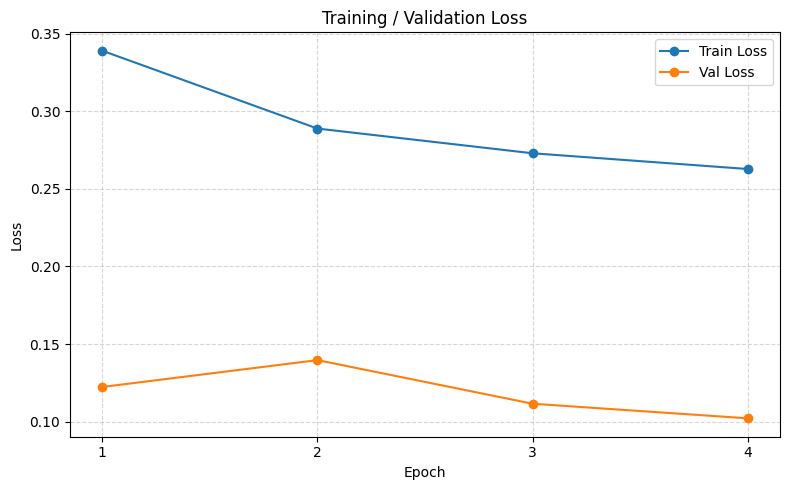

In [29]:
# 학습곡선 그래프
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

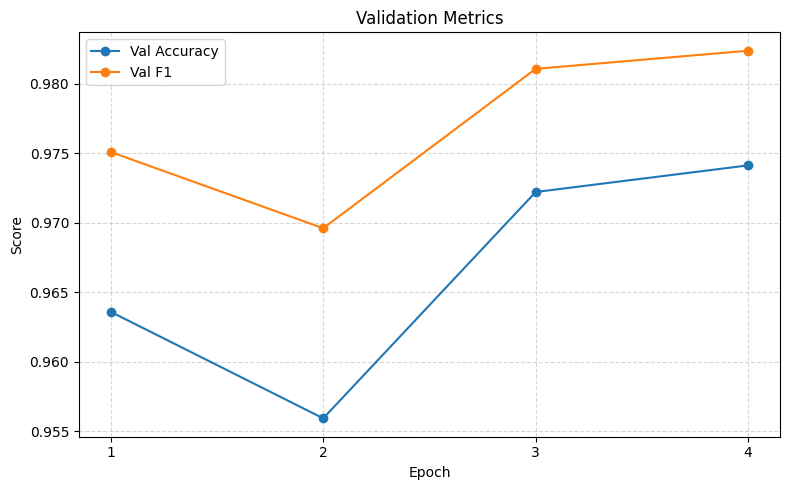

In [30]:
# Accuracy와 F1 그래프
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["val_acc"], marker="o", label="Val Accuracy")
plt.plot(epochs, history["val_f1"], marker="o", label="Val F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics")
plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 9. 테스트 데이터 예측하기

학습이 끝났으니 이제 우리 모델이 얼마나 잘 학습했는지 테스트해볼 차례입니다.

model.eval()로 모델을 평가 모드로 바꿉니다. 학습할 때와 예측할 때는 모델의 동작이 약간 다르기 때문입니다. torch.no_grad()는 메모리를 절약하기 위한 설정으로, 예측할 때는 가중치를 업데이트할 필요가 없으니까 관련 계산을 하지 않습니다.

예측 과정은 테스트 이미지를 모델에 넣고, 모델이 각 클래스별 점수를 반환하면, argmax로 가장 높은 점수의 클래스를 선택합니다. 그리고 결과를 CPU로 옮기고 numpy 배열로 변환한 후, 모든 예측 결과를 하나의 리스트에 모읍니다.

**[v3 변경]** 이 단계에서는 시드별로 저장된 확률 파일들을 불러와서 평균을 낸 뒤, 평균 확률이 가장 높은 클래스를 최종 예측으로 선택합니다.


In [31]:
import glob

# 앙상블에 사용할 확률 파일들 (같은 해상도의 모든 시드)
# 다른 설정의 결과도 섞고 싶으면 패턴을 "probs_*.npy" 로 바꾸세요
files = sorted(glob.glob(os.path.join(PROBS_DIR, f"probs_{TAG}_{IMG_SIZE}_s*.npy")))
print("앙상블에 사용할 파일 수:", len(files))
for f in files:
    print(" ", os.path.basename(f))

probs_all = [np.load(f) for f in files]
assert all(p.shape == probs_all[0].shape for p in probs_all), "파일마다 예측 개수가 다릅니다"
assert probs_all[0].shape[0] == len(test_dataset), "테스트 데이터 개수와 맞지 않습니다"

# 확률 평균 -> 가장 높은 클래스 선택
probs_mean = np.mean(probs_all, axis=0)
all_preds = probs_mean.argmax(1)

# 테스트 예측 비율 확인
print("예측 개수:", np.bincount(all_preds, minlength=2))
print("예측 비율:", np.bincount(all_preds, minlength=2) / len(all_preds))

앙상블에 사용할 파일 수: 3
  probs_v4_128_s0.npy
  probs_v4_128_s1.npy
  probs_v4_128_s2.npy
예측 개수: [199 425]
예측 비율: [0.31891026 0.68108974]


## 10. 제출 파일 만들기

마지막으로 우리의 예측 결과를 대회에 제출할 수 있는 형태로 만들어야 합니다.

대회에서는 보통 제출 양식을 제공합니다. sample_submission.csv 파일이 바로 그 양식이에요. 이 파일에는 테스트 이미지들의 파일명이 순서대로 들어있고, 우리는 여기에 예측한 라벨을 넣어주면 됩니다.

우리가 예측한 결과를 라벨 컬럼에 넣고, 새로운 CSV 파일로 저장합니다. 이 파일을 대회 사이트에 업로드하면 점수를 확인할 수 있습니다!


In [32]:
submission  = pd.read_csv("sample_submission.csv")
submission["label"] = all_preds

In [33]:
submission.to_csv(f"submit_{TAG}_ens_{IMG_SIZE}.csv", index=False)

테스트: 클래스 0로 예측된 이미지


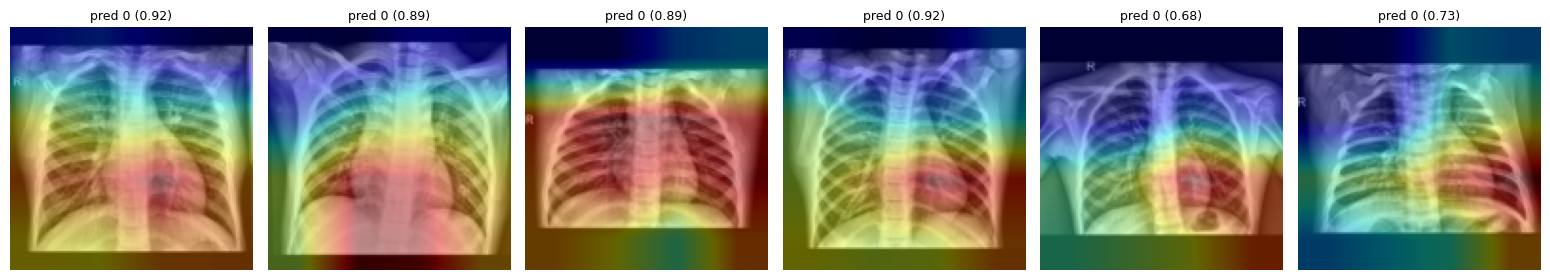

테스트: 클래스 1로 예측된 이미지


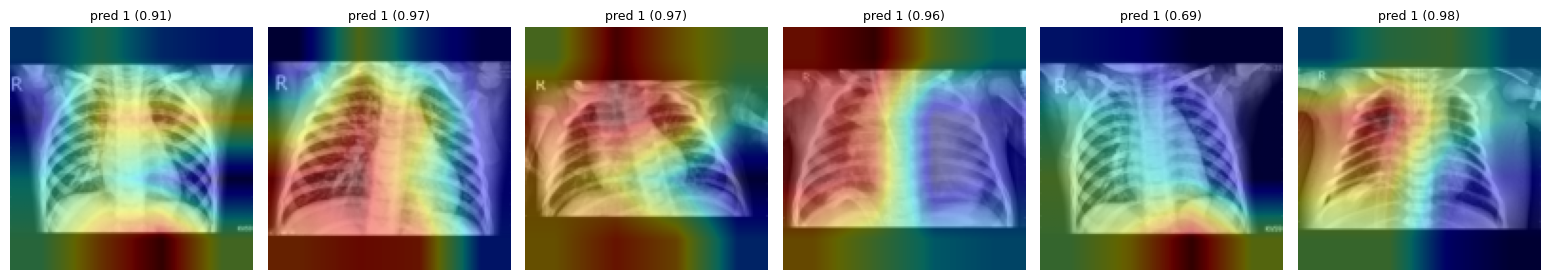

검증 이미지 (정답 라벨): [1, 1, 1, 1, 0, 1]


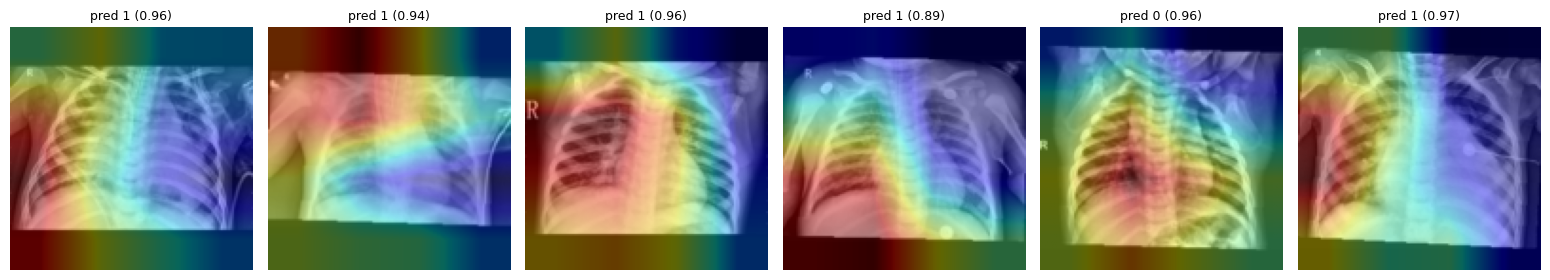

In [34]:
# Grad-CAM: 모델이 이미지의 어디를 보고 판단하는지 확인
# (학습이 끝난 마지막 시드의 best 모델로 확인합니다)
import cv2
import matplotlib.pyplot as plt

def grad_cam(model, x, class_idx=None):
    model.eval()
    feats, grads = [], []

    def fwd_hook(module, inp, out):
        feats.append(out)
        out.register_hook(lambda g: grads.append(g))

    handle = model.layer4.register_forward_hook(fwd_hook)
    out = model(x.unsqueeze(0).to(device))
    handle.remove()

    if class_idx is None:
        class_idx = out.argmax(1).item()

    model.zero_grad()
    out[0, class_idx].backward()

    f, g = feats[0][0], grads[0][0]          # (채널, H, W)
    weights = g.mean(dim=(1, 2))             # 채널별 중요도
    cam = torch.relu((weights[:, None, None] * f).sum(0))
    cam = (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
    prob = torch.softmax(out, 1)[0].detach().cpu().numpy()
    return cam, class_idx, prob


def show_cams(dataset, indices, ncols=6):
    n = len(indices)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.8 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, indices):
        item = dataset[int(idx)]
        x = item[0] if isinstance(item, tuple) else item
        cam, pred, prob = grad_cam(model, x)

        img = (x * NORM_STD[0] + NORM_MEAN[0]).clamp(0, 1).squeeze(0).numpy()
        cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))

        ax.imshow(img, cmap="gray")
        ax.imshow(cam_resized, cmap="jet", alpha=0.4)
        ax.set_title(f"pred {pred} ({prob[pred]:.2f})", fontsize=9)
    plt.tight_layout()
    plt.show()


rng = np.random.RandomState(1)

# 테스트 이미지: 클래스 0 / 클래스 1로 예측된 것들
for c in [0, 1]:
    cand = np.where(all_preds == c)[0]
    pick = rng.choice(cand, min(6, len(cand)), replace=False)
    print(f"테스트: 클래스 {c}로 예측된 이미지")
    show_cams(test_dataset, pick)

# 검증 이미지: 정답 라벨과 함께 확인
pick = rng.choice(val_indices, 6, replace=False)
print("검증 이미지 (정답 라벨):", [val_dataset.labels[i] for i in pick])
show_cams(val_dataset, pick)